In [1]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

In [2]:
games = pd.read_csv('../data/features.csv')

In [3]:
games.shape

(12300, 46)

In [4]:
home = games[games['HOME'] == 1]
away = games[games['HOME'] == 0]

In [5]:
home.shape

(6140, 46)

In [6]:
away.shape

(6160, 46)

## One row per game
Split the team rows into home and away, then merge them on GAME_ID so each row holds both teams side by side (_HOME / _AWAY). The 10 neutral-site games have no home row, so the merge drops them. Result: 6140 games.

In [7]:
matchups = pd.merge(home, away, on='GAME_ID', suffixes=('_HOME', '_AWAY'))

In [8]:
matchups.shape

(6140, 91)

In [9]:
features = ['ORTG_L10_HOME', 'DRTG_L10_HOME', 'REB_L10_HOME', 'WIN_L10_HOME', 'REST_DAYS_HOME', 'NET_L10_HOME',
            'ORTG_L10_AWAY', 'DRTG_L10_AWAY', 'REB_L10_AWAY', 'WIN_L10_AWAY', 'REST_DAYS_AWAY', 'NET_L10_AWAY']

## Drop games with missing history
Each team's first 10 games of a season have no 10-game average yet (NaN), and the model can't use NaN. Drop those games from matchups first, then rebuild X and y so they stay lined up.

In [10]:
matchups = matchups.dropna(subset=features)

## Target (y)
WIN_HOME: 1 if the home team won, 0 if it lost. This is what the model predicts.

In [11]:
y = matchups['WIN_HOME']

## Features (X)
The 12 pre-game columns the model learns from: the 6 features for each side (_HOME / _AWAY). Nothing from the game itself, so there's no leakage.

In [12]:
X = matchups[features]

In [13]:
X

,ORTG_L10_HOME,DRTG_L10_HOME,REB_L10_HOME,WIN_L10_HOME,REST_DAYS_HOME,NET_L10_HOME,ORTG_L10_AWAY,DRTG_L10_AWAY,REB_L10_AWAY,WIN_L10_AWAY,REST_DAYS_AWAY,NET_L10_AWAY
4,106.143592,115.501296,44.5,0.2,2.0,-9.357705,106.989696,106.781684,46.0,0.4,2.0,0.208012
5,107.265861,114.938874,44.1,0.2,1.0,-7.673013,97.847442,105.538512,43.6,0.2,2.0,-7.691069
6,109.055313,113.860172,44.4,0.3,2.0,-4.804859,103.901276,100.650043,45.1,0.5,2.0,3.251234
7,111.584134,112.482340,43.5,0.4,3.0,-0.898206,103.767842,107.063794,46.3,0.5,1.0,-3.295953
8,111.073568,111.668382,43.4,0.4,2.0,-0.594814,98.763808,101.358424,51.5,0.5,2.0,-2.594616
...,...,...,...,...,...,...,...,...,...,...,...,...
6135,109.853589,122.507639,38.1,0.0,2.0,-12.654050,111.886456,103.150981,45.1,1.0,3.0,8.735474
6136,107.046397,121.241994,37.2,0.1,2.0,-14.195597,112.209744,113.517211,45.2,0.6,2.0,-1.307468
6137,109.823497,124.924768,38.0,0.1,2.0,-15.101271,107.799997,121.877115,43.9,0.1,2.0,-14.077118
6138,109.403977,125.175397,39.1,0.1,2.0,-15.771419,109.383535,117.844016,45.5,0.2,2.0,-8.460480


In [14]:
X.shape, y.shape

((5362, 12), (5362,))

In [15]:
test_mask = matchups['SEASON_ID_HOME'] == 22025

## Train/test split (by time)
Train on 2021-22 to 2024-25, test on 2025-26. The model never sees a test game while learning, so the test score shows how it does on a season it hasn't seen. A random split would let it learn from later games to predict earlier ones.

In [16]:
X_train = X[~test_mask]
y_train = y[~test_mask]

X_test = X[test_mask]
y_test = y[test_mask]

In [17]:
X_train.shape, X_test.shape

((4291, 12), (1071, 12))

## Train the model
Logistic regression gives each of the 12 features a weight. .fit() learns those weights from the training games, nudging them until the predicted home-win probabilities best match the real results.

In [18]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

## Predict
The trained model guesses the winner of each 2025-26 game (1 = home win) using only the 12 pre-game features. It never saw these games' results.

In [19]:
preds = model.predict(X_test)

## Results
Accuracy: 64.8% on 2025-26. The baseline of always picking the home team gets 54.9% on the same games, so the model is +9.9 points better.

In [20]:
accuracy_score(y_test, preds)

0.6479925303454716

In [21]:
y_test.mean()

np.float64(0.5490196078431373)

## v2: Scaled features

StandardScaler puts every feature on the same scale: how many standard deviations above or below the training average. This makes the weights comparable and speeds up training. The scaler learns from X_train only, then applies those same numbers to X_test, so no test-season info leaks in.

In [22]:
scaler = StandardScaler()

In [23]:
X_train_scaled = scaler.fit_transform(X_train)

In [24]:
X_test_scaled = scaler.transform(X_test)

### Train v2
Same logistic regression as v1, trained on the scaled features. 

In [25]:
model_v2 = LogisticRegression(max_iter=1000)
model_v2.fit(X_train_scaled , y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### v2 Results
Accuracy: 64.9% vs v1's 64.8%. Training took 11 iterations vs v1's 394.

In [26]:
preds_v2 = model_v2.predict(X_test_scaled)

In [27]:
accuracy_score(y_test, preds_v2)

0.6489262371615313

In [28]:
pd.Series(model_v2.coef_[0], index=features).sort_values()

NET_L10_AWAY     -0.218197
ORTG_L10_AWAY    -0.195942
DRTG_L10_HOME    -0.155970
REST_DAYS_AWAY   -0.119944
REB_L10_HOME     -0.047155
WIN_L10_HOME     -0.017912
WIN_L10_AWAY     -0.012714
REB_L10_AWAY      0.036518
DRTG_L10_AWAY     0.095675
REST_DAYS_HOME    0.150038
ORTG_L10_HOME     0.211010
NET_L10_HOME      0.278299
dtype: float64

## Results chart (temporary)
Quick bar chart of test accuracy on 2025-26: the home-team baseline, my v1 model, and the betting-market range for reference. The market bar is the middle of 68-70%, so it's approximate. This will move into its own notebook later.

Matplotlib is building the font cache; this may take a moment.


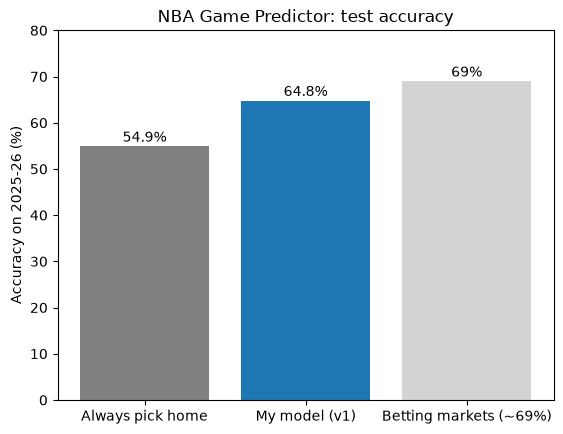

In [29]:
import matplotlib.pyplot as plt

labels = ['Always pick home', 'My model (v1)', 'Betting markets (~69%)']
values = [54.9, 64.8, 69]

plt.bar(labels, values, color=['gray', 'tab:blue', 'lightgray'])
plt.ylabel('Accuracy on 2025-26 (%)')
plt.title('NBA Game Predictor: test accuracy')
plt.ylim(0, 80)
for i, v in enumerate(values):
    plt.text(i, v + 1, f'{v}%', ha='center')
plt.savefig('../results.png', dpi=150, bbox_inches='tight')
plt.show()